# **KNN & PCA | Assignment (DA-AG-016)**

# **THEORY QUESTION**

### **1. What is K-Nearest Neighbors (KNN) and how does it work in both classification and regression problems?**

**Answer**:

**K-Nearest Neighbors (KNN)** is a simple, **non-parametric, instance-based (lazy) supervised learning** algorithm. It does not learn a model during training; it **stores the training data** and makes a prediction for a new point by looking at the **K closest training points** (its neighbours) under a distance measure such as Euclidean or Manhattan distance.

🔹 **Steps**
1. Choose K and a distance metric.
2. Compute the distance from the new point to every training point.
3. Pick the K nearest points.
4. Combine their labels/values to give the prediction.

🔹 **Classification**: the new point gets the **majority class** among its K neighbours (majority vote; optionally distance-weighted). *Example*: K = 5, three neighbours are "spam" and two are "not spam" → predict spam.

🔹 **Regression**: the prediction is the **average (or distance-weighted average) of the target values** of the K neighbours. *Example*: predicting a house price as the mean price of the 5 most similar houses.

🔹 **Key points**: small K gives low bias but high variance (overfitting); large K gives smoother, more stable predictions but may underfit. Features must be **scaled**, because distances are used. Prediction is slow on large data because every distance must be computed.

### **2. What is the Curse of Dimensionality and how does it affect KNN performance?**

**Answer**:

The **Curse of Dimensionality** refers to the problems that appear when the number of features (dimensions) becomes very large:

* The volume of the space grows exponentially, so the data becomes **sparse**: a fixed number of samples covers a tiny part of the space.
* **Distances lose meaning**: in high dimensions the nearest and farthest points become almost equally far away (the ratio of max to min distance approaches 1).
* More dimensions need **exponentially more data** to keep the same density.

🔹 **Effect on KNN** (which relies entirely on distance):
* "Nearest" neighbours are no longer truly similar, so predictions become **noisy and less accurate**.
* Irrelevant/noisy features add to the distance and **hide the useful signal**.
* Computation and memory cost increase (distance in many dimensions for every point).
* Higher risk of **overfitting** when samples are few.

🔹 **Remedies**: feature selection, dimensionality reduction (**PCA**), scaling, more data, and using a smaller number of informative features. The two demos below show the effect.

In [1]:
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

rng = np.random.default_rng(42)

# Demo 1: distances concentrate as dimensions grow (max/min distance ratio -> 1)
print("Demo 1: ratio of farthest to nearest distance from one point to 500 random points")
for dim in [2, 10, 100, 1000]:
    X = rng.random((500, dim)); q = rng.random(dim)
    dist = np.linalg.norm(X - q, axis=1)
    print(f"  dimensions = {dim:<5} max/min distance = {dist.max() / dist.min():7.2f}")

# Demo 2: adding useless noise features hurts KNN accuracy
X, y = load_wine(return_X_y=True)
X = StandardScaler().fit_transform(X)
print("\nDemo 2: KNN accuracy on Wine when random noise features are added")
for extra in [0, 10, 50, 200, 500]:
    Xn = np.hstack([X, rng.normal(size=(len(X), extra))]) if extra else X
    Xtr, Xte, ytr, yte = train_test_split(Xn, y, test_size=0.3, random_state=42, stratify=y)
    acc = KNeighborsClassifier(n_neighbors=5).fit(Xtr, ytr).score(Xte, yte)
    print(f"  {13 + extra:>4} features ({extra:>3} noise): accuracy = {acc:.4f}")

Demo 1: ratio of farthest to nearest distance from one point to 500 random points
  dimensions = 2     max/min distance =   76.45
  dimensions = 10    max/min distance =    3.42
  dimensions = 100   max/min distance =    1.41
  dimensions = 1000  max/min distance =    1.11

Demo 2: KNN accuracy on Wine when random noise features are added
    13 features (  0 noise): accuracy = 0.9444
    23 features ( 10 noise): accuracy = 0.9444
    63 features ( 50 noise): accuracy = 0.8889
   213 features (200 noise): accuracy = 0.6667
   513 features (500 noise): accuracy = 0.6296


### **3. What is Principal Component Analysis (PCA)? How is it different from feature selection?**

**Answer**:

**PCA** is an **unsupervised dimensionality-reduction** technique. It finds new, **uncorrelated (orthogonal) axes called principal components**, each a **linear combination of the original features**, ordered so that the first component captures the **maximum variance** in the data, the second captures the most remaining variance, and so on. Keeping only the first few components reduces the number of features while retaining most of the information.

🔹 **Steps**: standardise data → compute covariance matrix → find eigenvalues/eigenvectors → sort by eigenvalue → keep the top k eigenvectors → project the data onto them.

| | **PCA (feature extraction)** | **Feature selection** |
|---|---|---|
| **Idea** | Creates **new features** (combinations of all original features) | **Chooses a subset** of the **original features** and discards the rest |
| **Features after** | Transformed components (PC1, PC2, ...) | Original, named features |
| **Interpretability** | Lower (components are mixtures) | Higher (keeps real meaning) |
| **Uses target?** | No (unsupervised, based on variance) | Often yes (filter, wrapper, embedded methods) |
| **Handles correlation** | Removes correlation between features | Correlated features may remain |
| **Example** | 13 wine measurements → 2 components | Keep only alcohol, flavanoids, proline |

### **4. What are eigenvalues and eigenvectors in PCA, and why are they important?**

**Answer**:

For the **covariance matrix C** of the standardised data, an **eigenvector v** and its **eigenvalue λ** satisfy `C v = λ v`: multiplying C by v only **stretches** v by the factor λ and does not change its direction.

* **Eigenvectors** = the **directions (principal components)** along which the data varies. They are orthogonal to each other, and the data is projected onto them.
* **Eigenvalues** = the **amount of variance** the data has along each eigenvector.
* **Explained variance ratio** of component i = `λᵢ / Σλ`.

🔹 **Why important**
1. Sorting eigenvectors by eigenvalue ranks components by importance.
2. Keeping the eigenvectors with the **largest eigenvalues** keeps most of the information while reducing dimensions.
3. Small eigenvalues mark directions with little variance (often noise) that can be dropped.
4. The cumulative sum of eigenvalues tells how many components to keep (e.g. enough for 90–95% of the variance).

The demo shows that the eigen-decomposition of the covariance matrix gives exactly the same result as scikit-learn's PCA.

In [2]:
import numpy as np
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

Xs = StandardScaler().fit_transform(load_wine().data)
cov = np.cov(Xs, rowvar=False)                                 # 13 x 13 covariance matrix
eigvals, eigvecs = np.linalg.eigh(cov)
order = np.argsort(eigvals)[::-1]; eigvals, eigvecs = eigvals[order], eigvecs[:, order]

print("Top 5 eigenvalues (manual)      :", eigvals[:5].round(4))
print("Explained variance (sklearn PCA):", PCA().fit(Xs).explained_variance_[:5].round(4))
print("Explained variance ratio (manual):", (eigvals / eigvals.sum())[:5].round(4))
print("First eigenvector (PC1 direction):", eigvecs[:, 0].round(3))

Top 5 eigenvalues (manual)      : [4.7324 2.5111 1.4542 0.9242 0.858 ]
Explained variance (sklearn PCA): [4.7324 2.5111 1.4542 0.9242 0.858 ]
Explained variance ratio (manual): [0.362  0.1921 0.1112 0.0707 0.0656]
First eigenvector (PC1 direction): [-0.144  0.245  0.002  0.239 -0.142 -0.395 -0.423  0.299 -0.313  0.089
 -0.297 -0.376 -0.287]


### **5. How do KNN and PCA complement each other when applied in a single pipeline?**

**Answer**:

KNN suffers when there are **many features** (curse of dimensionality, noise, slow distance calculation), and PCA is exactly a tool to reduce these problems, so they work well together:

| KNN's weakness | How PCA helps |
|---|---|
| Distances become meaningless in high dimensions | Fewer, informative dimensions make distances meaningful again |
| Noisy/irrelevant features distort distance | Low-variance (noise) components are dropped |
| Correlated features count the same information twice | Components are **uncorrelated** |
| Slow prediction (many distances) | Fewer dimensions → faster distance computation, less memory |
| Overfitting with few samples | Fewer features lower the risk of overfitting |
| Hard to visualise | 2 or 3 components can be plotted to see class clusters |

🔹 **Standard pipeline**: `StandardScaler → PCA → KNN`, fitted with `sklearn.pipeline.Pipeline`, so that scaling and PCA are learned **only on the training data** (no data leakage) and the number of components and K can be tuned together with cross-validation.

🔹 **Caution**: PCA is unsupervised, so it keeps variance and not necessarily the class-separating information; the number of components should be validated by the KNN accuracy.

# **PRACTICAL QUESTIONS** (Wine dataset from `sklearn.datasets.load_wine()`)

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

wine = load_wine()
X, y = wine.data, wine.target
print("Wine dataset:", X.shape, "| classes:", [str(c) for c in wine.target_names], "| samples per class:", np.bincount(y).tolist())

# one common train/test split used in all questions (70/30, stratified, fixed seed)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

Wine dataset: (178, 13) | classes: ['class_0', 'class_1', 'class_2'] | samples per class: [59, 71, 48]


### **6. Train a KNN Classifier on the Wine dataset with and without feature scaling. Compare model accuracy in both cases.**

**Answer**:

In [4]:
# WITHOUT scaling
knn_raw = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
acc_raw = accuracy_score(y_test, knn_raw.predict(X_test))

# WITH scaling (scaler learned on the training data only, then applied to both sets)
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)
knn_scaled = KNeighborsClassifier(n_neighbors=5).fit(X_train_s, y_train)
acc_scaled = accuracy_score(y_test, knn_scaled.predict(X_test_s))

print(f"KNN accuracy WITHOUT scaling: {acc_raw:.4f}")
print(f"KNN accuracy WITH scaling   : {acc_scaled:.4f}")
print(f"Improvement from scaling    : {(acc_scaled - acc_raw) * 100:+.2f} percentage points")

print("\nFeature ranges (why scaling matters):")
print(pd.DataFrame({"min": X.min(0), "max": X.max(0)}, index=wine.feature_names).round(2).sort_values("max", ascending=False).head(4))

KNN accuracy WITHOUT scaling: 0.7222
KNN accuracy WITH scaling   : 0.9444
Improvement from scaling    : +22.22 percentage points

Feature ranges (why scaling matters):
                      min      max
proline            278.00  1680.00
magnesium           70.00   162.00
alcalinity_of_ash   10.60    30.00
alcohol             11.03    14.83


**Interpretation**: Without scaling, KNN reaches only **72.2%** because the feature *proline* (values in the hundreds to thousands) dominates the distance and other features hardly count. After `StandardScaler`, every feature contributes equally and accuracy rises to **94.4%**.

### **7. Train a PCA model on the Wine dataset and print the explained variance ratio of each principal component.**

**Answer**:

PCA is variance based, so the data is standardised first (otherwise *proline* would dominate the first component).

Explained variance ratio of each principal component:
  PC1 : 0.3620  (36.20%)   cumulative =  36.20%
  PC2 : 0.1921  (19.21%)   cumulative =  55.41%
  PC3 : 0.1112  (11.12%)   cumulative =  66.53%
  PC4 : 0.0707  ( 7.07%)   cumulative =  73.60%
  PC5 : 0.0656  ( 6.56%)   cumulative =  80.16%
  PC6 : 0.0494  ( 4.94%)   cumulative =  85.10%
  PC7 : 0.0424  ( 4.24%)   cumulative =  89.34%
  PC8 : 0.0268  ( 2.68%)   cumulative =  92.02%
  PC9 : 0.0222  ( 2.22%)   cumulative =  94.24%
  PC10: 0.0193  ( 1.93%)   cumulative =  96.17%
  PC11: 0.0174  ( 1.74%)   cumulative =  97.91%
  PC12: 0.0130  ( 1.30%)   cumulative =  99.20%
  PC13: 0.0080  ( 0.80%)   cumulative = 100.00%

Components needed for 90% variance: 8 | for 95% variance: 10


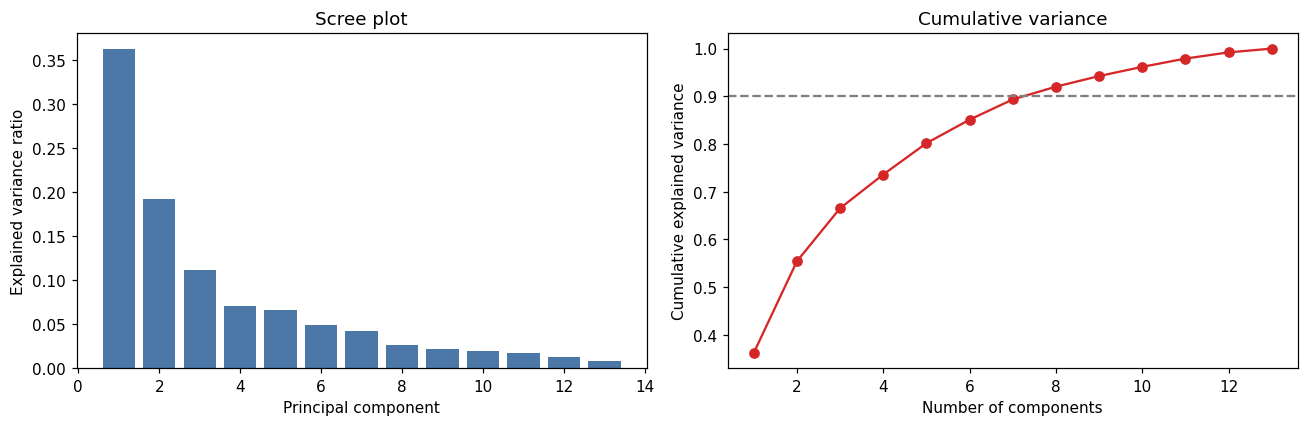

In [5]:
X_scaled = StandardScaler().fit_transform(X)
pca = PCA()                       # keep all 13 components
pca.fit(X_scaled)

ratio = pca.explained_variance_ratio_
print("Explained variance ratio of each principal component:")
for i, r in enumerate(ratio, start=1):
    print(f"  PC{i:<2}: {r:.4f}  ({r * 100:5.2f}%)   cumulative = {ratio[:i].sum() * 100:6.2f}%")

n90 = int(np.argmax(np.cumsum(ratio) >= 0.90)) + 1
n95 = int(np.argmax(np.cumsum(ratio) >= 0.95)) + 1
print(f"\nComponents needed for 90% variance: {n90} | for 95% variance: {n95}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(range(1, 14), ratio, color="#4c78a8"); ax[0].set(xlabel="Principal component", ylabel="Explained variance ratio", title="Scree plot")
ax[1].plot(range(1, 14), np.cumsum(ratio), marker="o", color="#d62728"); ax[1].axhline(0.9, linestyle="--", color="grey")
ax[1].set(xlabel="Number of components", ylabel="Cumulative explained variance", title="Cumulative variance")
plt.tight_layout(); plt.show()

**Interpretation**: PC1 explains **36.2%** and PC2 **19.2%** of the variance, so the first two components together keep **55.4%**. **8 components** are enough for 90% of the variance, so the 13 features are highly redundant.

### **8. Train a KNN Classifier on the PCA-transformed dataset (retain top 2 components). Compare the accuracy with the original dataset.**

**Answer**:

A `Pipeline` is used so that scaling and PCA are fitted on the training data only (no leakage).

KNN on original data (13 features, scaled): 0.9444
KNN on PCA data (2 components)            : 0.9444
Variance retained by 2 components         : 54.9%


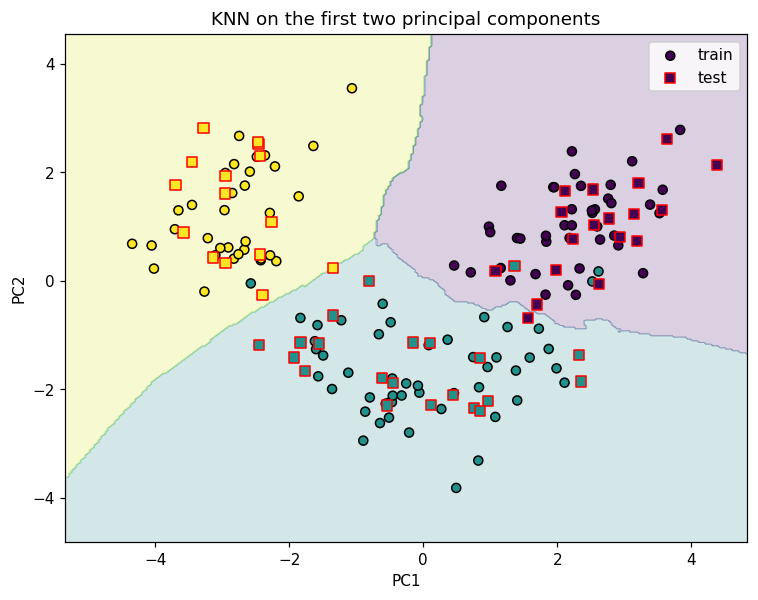

In [6]:
# Original (scaled) 13 features
orig = Pipeline([("scale", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=5))]).fit(X_train, y_train)
acc_orig = orig.score(X_test, y_test)

# PCA with top 2 components
pca2 = Pipeline([("scale", StandardScaler()), ("pca", PCA(n_components=2)), ("knn", KNeighborsClassifier(n_neighbors=5))]).fit(X_train, y_train)
acc_pca2 = pca2.score(X_test, y_test)

print(f"KNN on original data (13 features, scaled): {acc_orig:.4f}")
print(f"KNN on PCA data (2 components)            : {acc_pca2:.4f}")
print(f"Variance retained by 2 components         : {pca2['pca'].explained_variance_ratio_.sum() * 100:.1f}%")

# Visualise the 2D space and the KNN decision regions
Z_train = pca2[:-1].transform(X_train); Z_test = pca2[:-1].transform(X_test)
xx, yy = np.meshgrid(np.linspace(Z_train[:, 0].min() - 1, Z_train[:, 0].max() + 1, 300), np.linspace(Z_train[:, 1].min() - 1, Z_train[:, 1].max() + 1, 300))
zz = pca2["knn"].predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
plt.figure(figsize=(8, 6)); plt.contourf(xx, yy, zz, alpha=0.2, cmap="viridis")
plt.scatter(Z_train[:, 0], Z_train[:, 1], c=y_train, cmap="viridis", edgecolor="k", s=35, label="train")
plt.scatter(Z_test[:, 0], Z_test[:, 1], c=y_test, cmap="viridis", marker="s", edgecolor="r", s=45, label="test")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("KNN on the first two principal components"); plt.legend(); plt.show()

**Interpretation**: With only **2 components** (about 55% of the variance), KNN reaches **94.4%**, compared with **94.4%** on all 13 scaled features. PCA gives similar accuracy with far fewer features, faster distance computation and a plot that can be visualised in 2D. A small drop or gain is possible because PCA keeps variance, not necessarily class information.

### **9. Train a KNN Classifier with different distance metrics (euclidean, manhattan) on the scaled Wine dataset and compare the results.**

**Answer**:

In [7]:
X_train_s = StandardScaler().fit(X_train).transform(X_train)
X_test_s = StandardScaler().fit(X_train).transform(X_test)

results = []
for metric in ["euclidean", "manhattan"]:
    for k in [3, 5, 7, 9, 11]:
        knn = KNeighborsClassifier(n_neighbors=k, metric=metric).fit(X_train_s, y_train)
        results.append({"metric": metric, "k": k, "test_accuracy": knn.score(X_test_s, y_test)})
res = pd.DataFrame(results).pivot(index="k", columns="metric", values="test_accuracy")
print("Test accuracy by K and distance metric:\n", res.round(4))

# more reliable comparison: 5-fold cross-validation on the whole data (scaling inside the pipeline)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print("\n5-fold cross-validated accuracy (K = 5):")
cv_scores = {}
for metric in ["euclidean", "manhattan"]:
    pipe = Pipeline([("scale", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=5, metric=metric))])
    s = cross_val_score(pipe, X, y, cv=cv); cv_scores[metric] = s.mean()
    print(f"  {metric:<10} mean = {s.mean():.4f}  (std = {s.std():.4f})")

Test accuracy by K and distance metric:
 metric  euclidean  manhattan
k                           
3          0.9444     0.9630
5          0.9444     0.9815
7          0.9444     0.9815
9          0.9630     0.9815
11         0.9630     0.9630

5-fold cross-validated accuracy (K = 5):
  euclidean  mean = 0.9717  (std = 0.0181)
  manhattan  mean = 0.9663  (std = 0.0326)


**Interpretation**: At K = 5 the test accuracy is **94.4%** (Euclidean) and **98.1%** (Manhattan). In 5-fold cross-validation the means are **97.2%** and **96.6%**. Both metrics perform very similarly on the scaled Wine data (the differences are about one or two samples out of 54, so not significant). Manhattan distance is often a little more robust with many features or outliers, while Euclidean is the default and works well on compact clusters.

### **10. High-dimensional gene expression data: PCA + KNN pipeline for cancer classification**

**Answer**:

**Problem**: thousands of gene features but only tens or hundreds of patients (p ≫ n), so traditional models overfit and KNN distances become unreliable.

🔹 **1. Use PCA to reduce dimensionality**: standardise each gene, then project onto a small number of principal components. Genes are strongly correlated and mostly noise, so a few components capture the main biological variation. PCA is fitted **inside each cross-validation fold** (only on training patients) to avoid leakage.

🔹 **2. Decide how many components to keep**: use the **cumulative explained-variance curve** (e.g. 90 to 95%), look at the scree "elbow", and then **tune `n_components` by cross-validated accuracy** (the final choice is the smallest number that gives the best CV score).

🔹 **3. KNN after dimensionality reduction**: classify each patient by the majority class of the K most similar patients in the PCA space. Tune K (and distance metric) with the same cross-validation. It is simple, needs no training, and works well when classes form clusters.

🔹 **4. Evaluate the model**: **stratified k-fold cross-validation** (small sample size), a final hold-out test set, and metrics beyond accuracy: **confusion matrix, precision, recall, F1 per cancer type** (a missed cancer is costly). Compare against a baseline (KNN without PCA) and report variation across folds.

🔹 **5. Justify to stakeholders**: it reduces thousands of noisy features to a handful of components, **lowering overfitting**; it is **fast and transparent** (similar patients → similar diagnosis); every step is **validated without leakage** using a pipeline and cross-validation; results are **visualisable** (2D/3D patient maps); and it is cheap to retrain when new patients arrive. *Limitations to state honestly*: components are not directly interpretable as genes, so top-loading genes should be reviewed by domain experts; and the model needs external validation on an independent cohort before clinical use.

*The code uses **simulated** gene-expression data (90 patients, 2,000 genes, 3 cancer types, 100 marker genes per type, the rest is noise), because the real dataset is not provided. Replace `X_gene, y_gene` with the real data to use it.*

Gene data: (90, 2000) (patients x genes) | patients per cancer type: [30, 30, 30]

Baseline KNN on 2000 genes (5-fold CV): 0.8473
Components for 90% variance: 57 | for 95%: 62 (of 67 possible)

Best parameters: {'knn__metric': 'euclidean', 'knn__n_neighbors': 7, 'pca__n_components': 2}
Best cross-validated accuracy: 0.9846

Hold-out test accuracy: 1.0000
Confusion matrix:
 [[7 0 0]
 [0 8 0]
 [0 0 8]]

                precision    recall  f1-score   support

Cancer type A       1.00      1.00      1.00         7
Cancer type B       1.00      1.00      1.00         8
Cancer type C       1.00      1.00      1.00         8

     accuracy                           1.00        23
    macro avg       1.00      1.00      1.00        23
 weighted avg       1.00      1.00      1.00        23



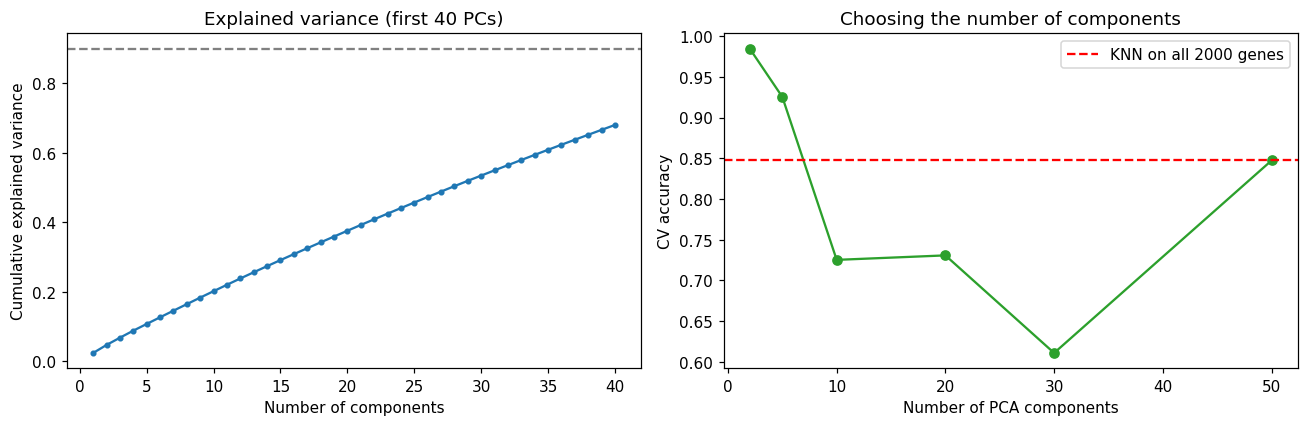

In [8]:
from sklearn.datasets import make_classification
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix

# ---- simulated gene expression data: many genes, few patients ----
# 90 patients, 2000 genes, 3 cancer types; each type has 100 "marker" genes with a modest mean shift, all other genes are pure noise
rng = np.random.default_rng(42)
y_gene = np.repeat([0, 1, 2], 30)
X_gene = rng.normal(size=(90, 2000))
for c in range(3):
    X_gene[y_gene == c, c * 100:(c + 1) * 100] += 0.7
print("Gene data:", X_gene.shape, "(patients x genes) | patients per cancer type:", np.bincount(y_gene).tolist())
Xg_tr, Xg_te, yg_tr, yg_te = train_test_split(X_gene, y_gene, test_size=0.25, random_state=42, stratify=y_gene)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ---- 1) baseline: KNN on all 2000 genes ----
base = Pipeline([("scale", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=5))])
base_cv = cross_val_score(base, Xg_tr, yg_tr, cv=cv).mean()
print(f"\nBaseline KNN on 2000 genes (5-fold CV): {base_cv:.4f}")

# ---- 2) how many components? explained-variance curve ----
Z = PCA().fit(StandardScaler().fit_transform(Xg_tr))
cum = np.cumsum(Z.explained_variance_ratio_)
print("Components for 90% variance:", int(np.argmax(cum >= 0.90)) + 1, "| for 95%:", int(np.argmax(cum >= 0.95)) + 1, f"(of {len(cum)} possible)")

# ---- 3) tune n_components and K together, PCA fitted inside each CV fold (no leakage) ----
pipe = Pipeline([("scale", StandardScaler()), ("pca", PCA(random_state=42)), ("knn", KNeighborsClassifier())])
grid = GridSearchCV(pipe, {"pca__n_components": [2, 5, 10, 20, 30, 50], "knn__n_neighbors": [3, 5, 7, 9],
                           "knn__metric": ["euclidean", "manhattan"]}, cv=cv, scoring="accuracy")
grid.fit(Xg_tr, yg_tr)
print("\nBest parameters:", grid.best_params_)
print(f"Best cross-validated accuracy: {grid.best_score_:.4f}")

# ---- 4) final evaluation on unseen patients ----
pred = grid.predict(Xg_te)
print(f"\nHold-out test accuracy: {accuracy_score(yg_te, pred):.4f}")
print("Confusion matrix:\n", confusion_matrix(yg_te, pred))
print("\n", classification_report(yg_te, pred, target_names=["Cancer type A", "Cancer type B", "Cancer type C"]))

# ---- 5) plots: variance curve and CV accuracy vs number of components ----
cvres = pd.DataFrame(grid.cv_results_)
by_n = cvres.groupby("param_pca__n_components")["mean_test_score"].max()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(1, 41), cum[:40], marker="o", ms=3); ax[0].axhline(0.9, linestyle="--", color="grey")
ax[0].set(xlabel="Number of components", ylabel="Cumulative explained variance", title="Explained variance (first 40 PCs)")
ax[1].plot(by_n.index.astype(int), by_n.values, marker="o", color="#2ca02c"); ax[1].axhline(base_cv, linestyle="--", color="red", label="KNN on all 2000 genes")
ax[1].set(xlabel="Number of PCA components", ylabel="CV accuracy", title="Choosing the number of components"); ax[1].legend()
plt.tight_layout(); plt.show()

**Interpretation**: KNN on all 2,000 genes gets **84.7%** in cross-validation. The tuned PCA + KNN pipeline (best settings: `{'knn__metric': 'euclidean', 'knn__n_neighbors': 7, 'pca__n_components': 2}`) gets **98.5%**, which is higher than the baseline, while using only **2 components instead of 2,000 genes** (1000x fewer features). On the held-out patients it reaches **100.0%** (only 23 patients, so treat this with caution; cross-validation is the more reliable figure). The main benefit of PCA here is a compact, less noisy, faster and more stable representation; whether accuracy also rises depends on how strong the class signal is, so always compare with the baseline as done here. (These numbers are for **simulated** data; with real data the same code selects the number of components automatically.)